# Black-Scholes PDE Solver

## 1. Goal

Implement finite difference PDE solver via three different methods:

- 1. Explicit

- 2. Implicit

- 3. Crank-Nicolson

and compare the following results:

- 1. Analytic formula

- 2. Monte Carlo

- 3. PDE solver

## 2. Preliminary

### 2.1 Analytic formula

In this experiment, we focus on the European put option. Black-Scholes equation is stated as follows

$$
\partial_t V+rS V_S+\frac{1}{2}\sigma^2 S^2 V_{SS}=rV.
$$

The analytic Black-Scholes formula for European put is 

$$
P_{BS}=Ke^{-rT}N(-d_2)-S_0 N(-d_1),
$$

where 

$$
d_1=\frac{1}{\sigma \sqrt{T}}\left[ \log\frac{S_0}{K}+(r+\frac{1}{2}\sigma^2)T\right],\quad d_2=d_1-\sigma \sqrt{T},
$$

and $N(x)$ is cumulative probability function for standard norm distribution.

### 2.2 Monte Carlo

In the risk-neutral measure, the stock price obeys the geometric Brownian motion

$$
dS=rSdt+\sigma SdW.
$$

Hence we get the stock price at time $T$

$$
S_T=S_0e^{(r-\frac{1}{2}\sigma^2)T}e^{\sigma \sqrt{T}Z},\qquad Z\sim N(0,1),
$$

as well as the Monte Carlo price for European put option

$$
P_{MC}=\frac{1}{n}e^{-rT}\sum_{k=1}^n (K-S_T^{(k)})^+. 
$$

### 2.3 Finite difference

Split time period $[0,T]$ into $N$ equally divided intervals via $N+1$ segment points

$$
0,\,\Delta t,\,2\Delta t,\,\cdots,\, N\Delta t,\qquad \Delta t=\frac{T}{N}.  
$$

Suppose $S_{max}$ is high enough such that when the stock price reaches this price, the put option is deep out of the money. We split 
$S_{max}$ into $M$ intervals with the same size $\Delta S=S_{max}/M$ and derive corresponding points

$$
0,\,\Delta S,\,2\Delta S,\, \cdots,\, M\Delta S,\qquad \Delta S=\frac{S_{max}}{M}.
$$

We now have the time-space grid for put option $p_{i,j}=p(i\Delta t,j\Delta S)$. Impose the boundary conditions 

$$
p_{N,j}=(K-j\Delta S)^+,
$$

$$
p_{i,0}=Ke^{-r(T-i\Delta t)},\qquad p_{i,M}=0. 
$$

Denote the finite difference operator $L_h$ as 

$$
L_h p_{i,j}=\alpha_j p_{i,j-1}+\beta_j p_{i,j}+\gamma_j p_{i,j+1},
$$

here the coefficients are 

$$
\begin{aligned}
&\alpha_j=\frac{1}{2}\sigma^2j^2-\frac{1}{2}rj,\\
&\beta_j=-\sigma^2j^2-r,\\
&\gamma_j=\frac{1}{2}\sigma^2j^2+\frac{1}{2}rj. 
\end{aligned}
$$

- Explicit finite difference solver

We evaluate the spatial derivative terms at the known time level $t_{i+1}$, while the discount term $-rp$ is evaluated at $t_i$.

Since $L_h$ includes the discount term $-rp$, the finite difference scheme is

$$
\frac{p_{i+1,j}-p_{i,j}}{\Delta t}
+L_hp_{i+1,j}
+rp_{i+1,j}-rp_{i,j}=0.
$$

Hence we get the explict PDE solver 

$$
p_{i,j}=a_j p_{i+1,j-1}+b_j p_{i+1,j}+c_j p_{i+1,j+1},
$$

where 

$$
\begin{aligned}
&a_j=\frac{1}{1+r\Delta t}(-\frac{1}{2}rj\Delta t+\frac{1}{2}\sigma^2j^2\Delta t),\\
&b_j=\frac{1}{1+r\Delta t}(1-\sigma^2j^2\Delta t)\\
&c_j=\frac{1}{1+r\Delta t}(\frac{1}{2}rj\Delta t+\frac{1}{2}\sigma^2j^2\Delta t).  
\end{aligned}
$$

- Implicit finite difference solver

$$
p_{i,j}=p_{i+1,j}+\Delta t L_h p_{i,j}
$$

derives the implicit PDE solver

$$
\begin{pmatrix}
b_1&c_1&0&\cdots&0\\
a_2&b_2&c_2&\cdots&0\\
0&a_3&b_3&\ddots&\vdots\\
\vdots&\ddots&\ddots&\ddots&c_{M-2}\\
0&\cdots&0&a_{M-1}&b_{M-1}
\end{pmatrix}
\begin{pmatrix}
p_{i,1}\\
p_{i,2}\\
\vdots\\
p_{i,M-2}\\
p_{i,M-1}
\end{pmatrix}
=
\begin{pmatrix}
p_{i+1,1}-a_1p_{i,0}\\
p_{i+1,2}\\
\vdots\\
p_{i+1,M-2}\\
p_{i+1,M-1}-c_{M-1}p_{i,M}
\end{pmatrix},
$$

where 

$$
\begin{aligned}
a_j&=\frac{\Delta t}{2}(rj-\sigma^2j^2),\\
b_j&=1+\Delta t(\sigma^2j^2+r),\\
c_j&=-\frac{\Delta t}{2}(rj+\sigma^2j^2).
\end{aligned}
$$

- Crank-Nicolson

$$
p_{i,j}=p_{i+1,j}+\frac{\Delta t}{2}(L_h p_{i,j}+L_h p_{i+1,j})
$$

and we can have 

$$
\begin{pmatrix}
b_1^*&c_1^*&&\\
a_2^*&b_2^*&c_2^*&\\
&\ddots&\ddots&\ddots\\
&&a_{M-1}^*&b_{M-1}^*
\end{pmatrix}
\begin{pmatrix}
p_{i,1}\\
p_{i,2}\\
\vdots\\
p_{i,M-1}
\end{pmatrix}
=
\begin{pmatrix}
\widetilde b_1^*&-c_1^*&&\\
-a_2^*&\widetilde b_2^*&-c_2^*&\\
&\ddots&\ddots&\ddots\\
&&-a_{M-1}^*&\widetilde b_{M-1}^*
\end{pmatrix}
\begin{pmatrix}
p_{i+1,1}\\
p_{i+1,2}\\
\vdots\\
p_{i+1,M-1}
\end{pmatrix}
+
\begin{pmatrix}
-a_1^*p_{i+1,0}-a_1^*p_{i,0}\\
0\\
\vdots\\
0\\
-c_{M-1}^*p_{i+1,M}-c_{M-1}^*p_{i,M}
\end{pmatrix}.
$$

The coefficients are the following 

$$
\begin{aligned}
a_j^*&=\frac{\Delta t}{4}(rj-\sigma^2j^2),\\
b_j^*&=1+\frac{\Delta t}{2}(\sigma^2j^2+r),\\
c_j^*&=-\frac{\Delta t}{4}(\sigma^2j^2+rj),\\
\widetilde b_j^*&
=1-\frac{\Delta t}{2}(\sigma^2j^2+r).
\end{aligned}
$$

# 3. Experiment

Consider a $5$-month European put option on a non-dividend-paying stock when the stock price is $\$50$, the strike price is $\$50$, the risk-free interest rate is $10\%$ per annum, and the volatility is $40\%$ per annum. This means that $S_0=50,K=50,r=0.1,\sigma=0.4,T=0.4167$.


The exact put price form BS formula is: 4.0761.

For N in [1000, 1500, 2000, 3000, 5000, 10000], 
the Monte Carlo simulation prices are: [4.0762 4.0702 4.0853 4.0812 4.0783 4.0727] respectively,
the corresponding errors are: [0.1746 0.1468 0.1339 0.1038 0.0809 0.0539].


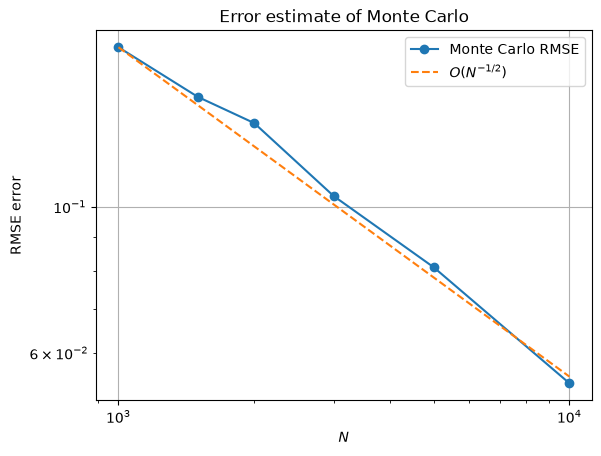

Estimated slope: -0.5144159371496179.


In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import analytic as an 
import monte_carlo as mc
import finite_difference as fd

S0=50;K=50;T=0.4167;r=0.1;sigma=0.4


# exact put option price form bs formula 
put_bs=an.black_scholes_europut(S0,K,T,r,sigma)
print()
print(f'The exact put price form BS formula is: {put_bs:.4f}.')


# Monte Carlo
np.random.seed(2026) # Reproducibility
N_interval=[1000,1500,2000,3000,5000,10000]
price_mc=[]
error_mc=[]
for N in N_interval:
    temp=[]
    repeat=500
    for _ in range(repeat):
        temp.append(mc.monte_carlo_put(S0,K,T,r,sigma,N)[0])
    temp=np.array(temp)

    price_cur=np.mean(temp)
    price_mc.append(price_cur)
    error_mc.append(np.sqrt(
        np.mean((temp-put_bs)**2)
    ))
price_mc=np.array(price_mc)
error_mc=np.array(error_mc)
print()
print(f'For N in {N_interval}, \nthe Monte Carlo simulation prices are: {np.round(price_mc,4)} respectively,')
print(f'the corresponding errors are: {np.round(error_mc,4)}.')

# Plot
N_interval=np.array(N_interval)
reference_mc=(N_interval/N_interval[0])**(-0.5)*error_mc[0]
plt.loglog(N_interval,error_mc,'o-',label='Monte Carlo RMSE')
plt.loglog(N_interval,reference_mc,'--',label=r'$O(N^{-1/2})$')
plt.xlabel(r'$N$')
plt.ylabel(r'RMSE error')
plt.title(r'Error estimate of Monte Carlo')
plt.legend()
plt.grid()
plt.show()

slope,intercept=np.polyfit(np.log(N_interval),np.log(error_mc),1)
print(f'Estimated slope: {slope}.')


The exact put price form BS formula is: 4.0761.

For N in [1000, 2000, 4000, 8000, 16000, 32000], 
the explicit solver gives put price: [4.06166731 4.06137432 4.06122783 4.06115459 4.06111797 4.06109966], 
the implicit solver gives put price: [4.06043281 4.06075707 4.06091921 4.06100028 4.06104081 4.06106108], 
the Crank Nicolson solver gives put price: [4.06108151 4.06108139 4.06108136 4.06108135 4.06108135 4.06108135].

order estimate for explicit: [1.00005227 1.00002614 1.0000129  1.0000067 ].
order estimate for implicit: [0.9999338  0.99996691 0.9999834  0.99999194].
order estimate for Crank-Nicolson: [1.99999493 2.00014439 1.99916482 2.00728972].


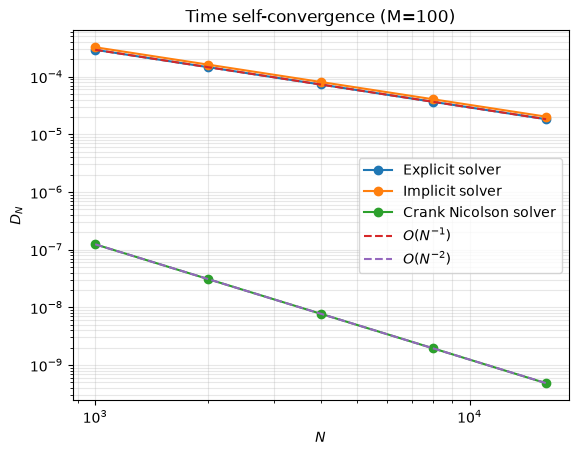

In [2]:
# Time Convergence
Smax=200
M=100
N_interval=[1000,2000,4000,8000,16000,32000]

# exact put option price form bs formula 
put_bs=an.black_scholes_europut(S0,K,T,r,sigma)
print(f'The exact put price form BS formula is: {put_bs:.4f}.')

# finite difference PDE solver
put_explicit=[]
put_implicit=[]
put_ck=[]
for N in N_interval:
    put_explicit.append(fd.bs_put_explicit(S0,K,T,r,sigma,M,N,Smax))
    put_implicit.append(fd.bs_put_implicits(S0,K,T,r,sigma,M,N,Smax))
    put_ck.append(fd.bs_put_CrankNicolson(S0,K,T,r,sigma,M,N,Smax))

put_explicit=np.array(put_explicit)
put_implicit=np.array(put_implicit)
put_ck=np.array(put_ck)
print()
print(f'For N in {N_interval}, \nthe explicit solver gives put price: {np.round(put_explicit,8)}, \nthe implicit solver gives put price: {np.round(put_implicit,8)}, \nthe Crank Nicolson solver gives put price: {np.round(put_ck,8)}.')

# D_N=|P_{M,2N}(0,S0)-P_{M,N}(0,S0)|
D_explicit=np.abs(put_explicit[:-1]-put_explicit[1:])
D_implicit=np.abs(put_implicit[:-1]-put_implicit[1:])
D_ck=np.abs(put_ck[:-1]-put_ck[1:])

# Order estimation
## p=log_2(D_{N}/D_{2N})
p_explicit=np.log2(D_explicit[:-1]/D_explicit[1:])
p_implicit=np.log2(D_implicit[:-1]/D_implicit[1:])
p_ck=np.log2(D_ck[:-1]/D_ck[1:])
print()
print(f'order estimate for explicit: {p_explicit}.')
print(f'order estimate for implicit: {p_implicit}.')
print(f'order estimate for Crank-Nicolson: {p_ck}.')

# Plot 
N_plot=np.array(N_interval[:-1])
ref_first=D_explicit[0]*(N_plot/N_plot[0])**(-1)
ref_second=D_ck[0]*(N_plot/N_plot[0])**(-2)

plt.loglog(N_plot,D_explicit,'o-',label=r'Explicit solver')
plt.loglog(N_plot,D_implicit,'o-',label=r'Implicit solver')
plt.loglog(N_plot,D_ck,'o-',label=r'Crank Nicolson solver')

plt.loglog(N_plot,ref_first,'--',label=r'$O(N^{-1})$')
plt.loglog(N_plot,ref_second,'--',label=r'$O(N^{-2})$')

plt.xlabel(r'$N$')
plt.ylabel(r'$D_N$')
plt.title(r'Time self-convergence (M=100)')
plt.grid(True,which='both',alpha=0.3)
plt.legend()
plt.show()



The exact put price form BS formula is: 4.0761.

For M in [40, 80, 160, 320, 640], 
Crank Nicolson gives put price: [3.97986443 4.05257439 4.07024932 4.07463964 4.07573548].

Order estimates for Crank Nicolson are: [2.0323097  2.00744338 2.00182776 2.00045521].


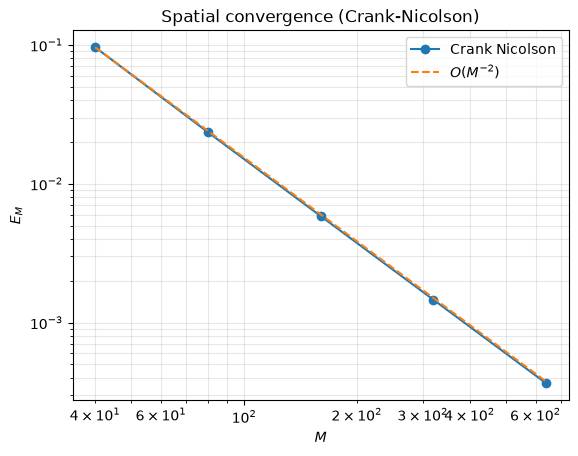

In [3]:
# Spatial Convergence
N=42000
M_interval=[40,80,160,320,640]

# exact put option price form bs formula 
put_bs=an.black_scholes_europut(S0,K,T,r,sigma)
print(f'The exact put price form BS formula is: {put_bs:.4f}.')

# Crank Nicolson
put_ck=[]
for M in M_interval:
    put_ck.append(fd.bs_put_CrankNicolson(S0,K,T,r,sigma,M,N,Smax))

put_ck=np.array(put_ck)
print()
print(f'For M in {M_interval}, \nCrank Nicolson gives put price: {np.round(put_ck,8)}.')

# error estimate
## E_M=|P_{N,M}(0,S0)-P_bs|; p=log_2(E_M/E_{2M})
error_ck=np.abs(put_bs-put_ck)
p_ck=np.log2(error_ck[:-1]/error_ck[1:])
print()
print(f'Order estimates for Crank Nicolson are: {p_ck}.')

# Plot
M_interval=np.array(M_interval)
ref_second=error_ck[0]*(M_interval/M_interval[0])**(-2)

plt.loglog(M_interval,error_ck,'o-',label=r'Crank Nicolson')
plt.loglog(M_interval,ref_second,'--',label=r'$O(M^{-2})$')

plt.xlabel(r'$M$')
plt.ylabel(r'$E_M$')
plt.title(r'Spatial convergence (Crank-Nicolson)')
plt.legend()
plt.grid(True,which='both',alpha=0.3)
plt.show()



In [4]:
# Comparison of different pricing methods
from time import perf_counter
import pandas as pd

M=200;N=8000;Smax=200

# BS formula of European put option
put_bs=an.black_scholes_europut(S0,K,T,r,sigma)

# Monte Carlo
np.random.seed(2026)  # Reproducibility
start=perf_counter()
put_mc, _, se, CI=mc.monte_carlo_put(S0,K,T,r,sigma,N=3000)
runtime_mc=perf_counter()-start

# Explicit
start=perf_counter()
put_explicit=fd.bs_put_explicit(S0,K,T,r,sigma,M,N,Smax)
runtime_explicit=perf_counter()-start

# Implicit
start=perf_counter()
put_implicit=fd.bs_put_implicits(S0,K,T,r,sigma,M,N,Smax)
runtime_implicit=perf_counter()-start

# CN
start=perf_counter()
put_cn=fd.bs_put_CrankNicolson(S0,K,T,r,sigma,M,N,Smax)
runtime_cn=perf_counter()-start

# Make results frame
results={
    'Black-Scholes':put_bs,
    'Monte Carlo':put_mc,
    'Explicit':put_explicit,
    'Implicit':put_implicit,
    'Crank-Nicolson':put_cn
}

runtimes={
    'Black-Scholes':None,
    'Monte Carlo':runtime_mc,
    'Explicit':runtime_explicit,
    'Implicit':runtime_implicit,
    'Crank-Nicolson':runtime_cn
}
df=pd.DataFrame({
    'Method':list(results.keys()),
    'Price':list(results.values()),
    'Runtime (s)':list(runtimes.values())
})

# Calculate absolute errors
df['Absolute Error']=abs(df['Price']-put_bs)

# Adjust column order
df=df[['Method','Price','Absolute Error','Runtime (s)']]

# Display formatted table
display(
    df.style.format({
        'Price': '{:.6f}',
        'Absolute Error': '{:3e}',
        'Runtime (s)': '{:.6f}'
    },na_rep='-').hide(axis='index')
)

print(f'MC Standard Error: {se:.6f}')
print(f'MC 95% CI: [{CI[0]:.6f}, {CI[1]:.6f}]')



Method,Price,Absolute Error,Runtime (s)
Black-Scholes,4.076101,0.000000e+00,-
Monte Carlo,3.940203,1.358981e-01,0.000253
Explicit,4.072431,3.669836e-03,0.041383
Implicit,4.072278,3.823051e-03,0.248023
Crank-Nicolson,4.072358,3.742542e-03,0.283862


MC Standard Error: 0.105127
MC 95% CI: [3.734154, 4.146251]


# 4. Conclusions

In this project, we compare three different methods when pricing European put option: BS formula, Monte Carlo Simulation and finite difference, the last one contains explicit, implicit and Crank Nicolson strategies. 

The Monte Carlo simulation holds error estimate of $O(N^{-1/2})$ where $N$ is the number of sample path. The experiments confirm first-order temporal convergence for the explicit and implicit schemes and second-order temporal convergence for Crank–Nicolson. The second-order spatial accuracy of the central difference discretization is numerically verified using the Crank–Nicolson scheme.

As we can see from the last table, the runtime of implicit and CN are longer compared with other methods. This is for the reason that they carry out linear equations solver to get the option price.